### Dataset Link: https://github.com/piush-ml/review-sentiment-analysis-dataset/tree/main/data

# Importing Necessary Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Loading the Datasets

In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
sample = pd.read_csv("sample.csv")

In [3]:
train.head()

,id,review_date,title,review_text,product_category,user_country,verified_purchase,price,discount,rating,helpful_votes,total_votes,sentiment
0,0,2022-01-31,NaN,VERY BAD QUALITY AND DISAPPOINTING EXPERIENCE....,Home,UK,True,69.44,0.30,2,5,6,negative
1,1,2022-12-30,Bad Purchase,Excellent performance and great value. Rating:...,Books,UK,True,40.69,0.49,3,3,6,neutral
2,2,2021-05-10,Best Buy,Very bad quality and disappointing experience....,Books,Australia,True,40.52,0.38,4,1,5,positive
3,3,2022-07-18,Okay Item,Very bad quality and disappointing experi...,Electronics,Australia,True,41.96,0.25,3,9,16,neutral
4,4,2022-02-04,NaN,THIS PRODUCT IS AMAZING AND WORKS PERFECTLY. R...,Clothing,Canada,False,93.21,0.12,5,6,11,positive


In [4]:
sample.head()

,id,sentiment
0,20000,NaN
1,20001,NaN
2,20002,NaN
3,20003,NaN
4,20004,NaN


# Exploratory Data Analysis

## Question 1

What is the shape of the train dataset?

In [5]:
train.shape

(20000, 13)

## Question 2

After separating the target from the features, what is the shape of the feature matrix (train set)?

In [6]:
X = train.drop(columns=['sentiment'])
y = train['sentiment']

X.shape, y.shape

((20000, 12), (20000,))

In [7]:
# Alternate syntax
X, y = train.drop('sentiment', axis=1), train['sentiment']
X.shape, y.shape

((20000, 12), (20000,))

## Question 3

How many null values are there in each column of feature matrix? How many duplicate values are present in the feature matrix?

In [8]:
X.isnull().sum()

id                      0
review_date             0
title                1400
review_text          1400
product_category        0
user_country         1400
verified_purchase       0
price                1400
discount                0
rating                  0
helpful_votes           0
total_votes             0
dtype: int64

In [9]:
# Alternate syntax
X.isna().sum()

id                      0
review_date             0
title                1400
review_text          1400
product_category        0
user_country         1400
verified_purchase       0
price                1400
discount                0
rating                  0
helpful_votes           0
total_votes             0
dtype: int64

In [10]:
X.duplicated().sum()

np.int64(0)

## Question 4

Display the descriptive statistics for the numerical columns of the feature matrix in tabular format.

In [11]:
X.describe()

,id,price,discount,rating,helpful_votes,total_votes
count,20000.000000,18600.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,9999.500000,54.591945,0.251401,3.459100,5.002100,12.022250
std,5773.647028,46.858794,0.144226,1.281487,2.233908,4.836375
min,0.000000,-208.000000,0.000000,1.000000,0.000000,0.000000
25%,4999.750000,30.507500,0.130000,3.000000,3.000000,8.000000
50%,9999.500000,51.180000,0.250000,4.000000,5.000000,12.000000
75%,14999.250000,71.815000,0.380000,5.000000,6.000000,16.000000
max,19999.000000,754.300000,0.500000,5.000000,20.000000,30.000000


## Question 5

Using a single command, check for the null values as well as the data type of each column of the feature matrix.

In [12]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 20000 non-null  int64  
 1   review_date        20000 non-null  object 
 2   title              18600 non-null  object 
 3   review_text        18600 non-null  object 
 4   product_category   20000 non-null  object 
 5   user_country       18600 non-null  object 
 6   verified_purchase  20000 non-null  bool   
 7   price              18600 non-null  float64
 8   discount           20000 non-null  float64
 9   rating             20000 non-null  int64  
 10  helpful_votes      20000 non-null  int64  
 11  total_votes        20000 non-null  int64  
dtypes: bool(1), float64(2), int64(4), object(5)
memory usage: 1.7+ MB


## Question 6

Is the target variable balanced? What are the respective proportions of each of the target labels?

In [13]:
y.value_counts()

sentiment
positive    11069
negative     4917
neutral      4014
Name: count, dtype: int64

In [14]:
# To get the proportions
y.value_counts(normalize=True)

sentiment
positive    0.55345
negative    0.24585
neutral     0.20070
Name: proportion, dtype: float64

## Question 7

For the target variable, use an appropriate plot to visualize the distribution of the labels.

<Axes: xlabel='sentiment', ylabel='Count'>

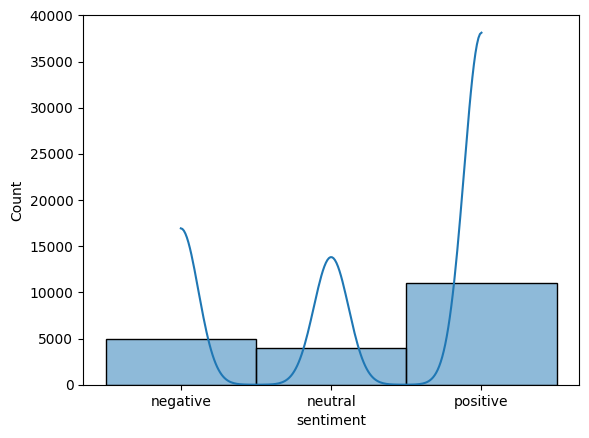

In [15]:
sns.histplot(y, kde=True)

## Question 8

Identify the numerical and categorical columns in the feature matrix.

In [16]:
cat = X.select_dtypes(include=['object', 'boolean']).columns.to_list()
num = X.select_dtypes(exclude=['object','boolean']).columns.to_list()

In [17]:
cat

['review_date',
 'title',
 'review_text',
 'product_category',
 'user_country',
 'verified_purchase']

In [18]:
num

['id', 'price', 'discount', 'rating', 'helpful_votes', 'total_votes']

In [19]:
# Alternate solution
cat = X.select_dtypes(exclude=np.number).columns.to_list()
num = X.select_dtypes(include=np.number).columns.to_list()
print(cat)
print(num)

['review_date', 'title', 'review_text', 'product_category', 'user_country', 'verified_purchase']
['id', 'price', 'discount', 'rating', 'helpful_votes', 'total_votes']


## Question 9

Convert the `review_date` column into `datetime` format.

In [20]:
X['review_date'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 20000 entries, 0 to 19999
Series name: review_date
Non-Null Count  Dtype 
--------------  ----- 
20000 non-null  object
dtypes: object(1)
memory usage: 156.4+ KB


In [21]:
X['review_date'] = pd.to_datetime(X['review_date'])
X['review_date'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 20000 entries, 0 to 19999
Series name: review_date
Non-Null Count  Dtype         
--------------  -----         
20000 non-null  datetime64[ns]
dtypes: datetime64[ns](1)
memory usage: 156.4 KB


## Question 10

Handle the missing values as follows:
- Impute categorical features with 'unknown'
- Impute numerical features with their corresponding mean value

In [22]:
print("\n Handling missing values\n")
for col in cat:
    X[col] = X[col].fillna('unknown')

for col in num:
    mean = X[col].mean()
    X[col] = X[col].fillna(mean)
print("\nMissing values handled.\n")
print("Sanity check:")
X.isnull().sum()


 Handling missing values


Missing values handled.

Sanity check:


id                   0
review_date          0
title                0
review_text          0
product_category     0
user_country         0
verified_purchase    0
price                0
discount             0
rating               0
helpful_votes        0
total_votes          0
dtype: int64

## Question 11

Plot histograms for each numeric variable (feature)

Saved 'numeric_histograms.png'


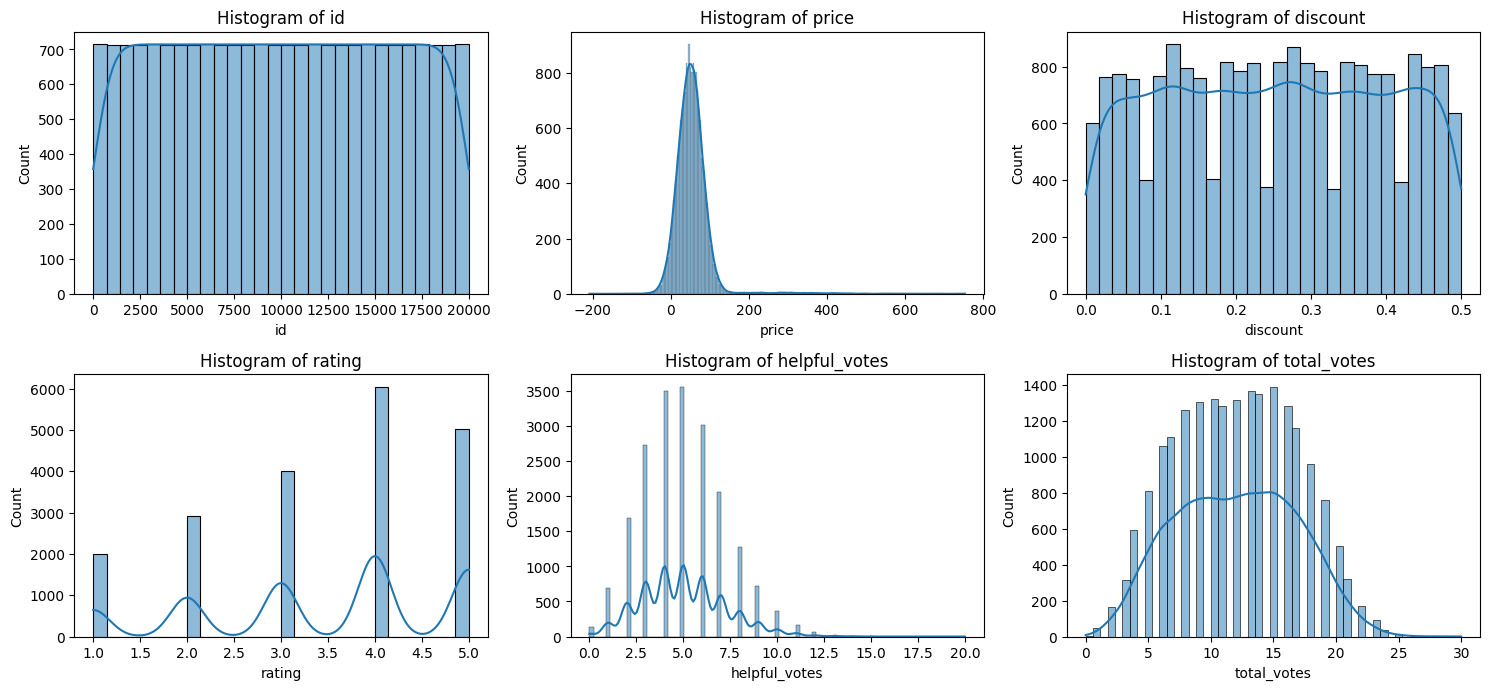

In [23]:
plt.figure(figsize=(15, 10))
for i, col in enumerate(num):
    plt.subplot(3, 3, i + 1)
    sns.histplot(train[col], kde=True)
    plt.title(f'Histogram of {col}')
plt.tight_layout()
plt.savefig('numeric_histograms.png')
print("Saved 'numeric_histograms.png'")

## Question 12

Plot a box plot for all numerical features

Saved 'numeric_boxplots.png'


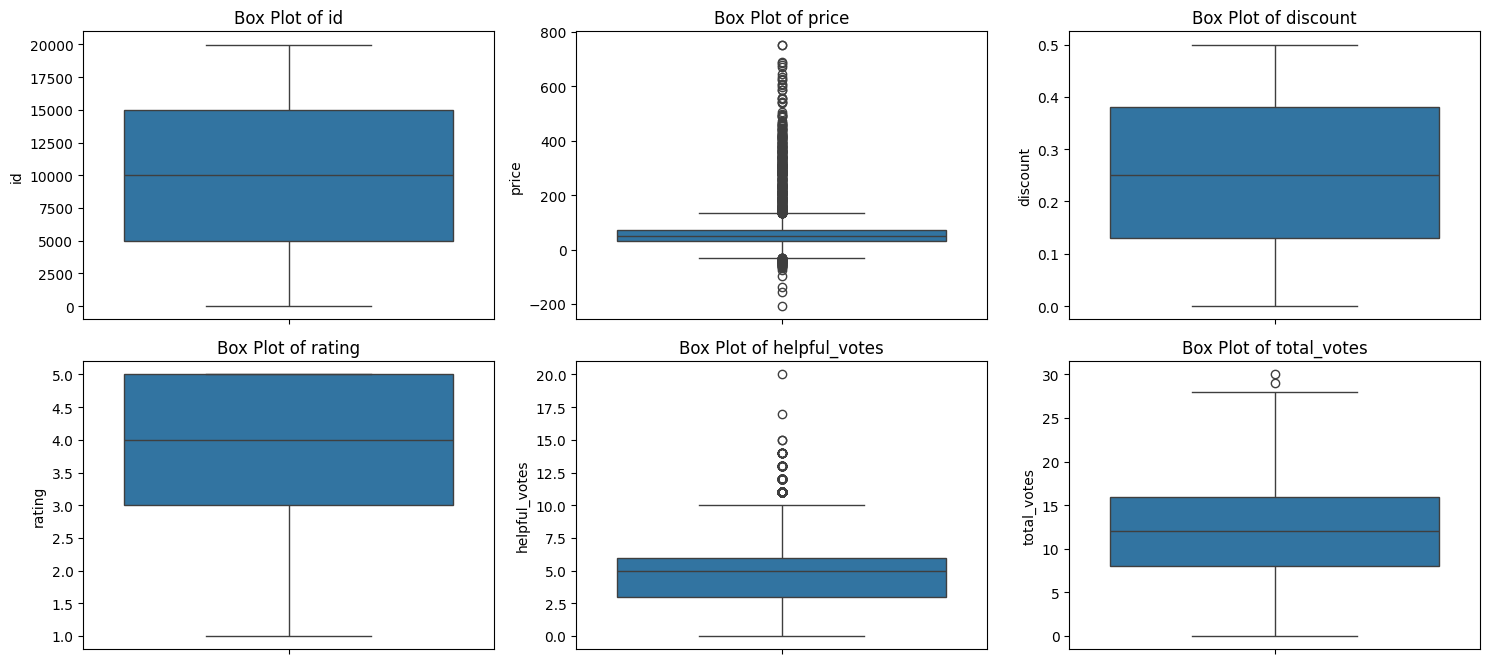

In [24]:
plt.figure(figsize=(15, 10))
for i, col in enumerate(num):
    plt.subplot(3, 3, i + 1)
    sns.boxplot(y=train[col])
    plt.title(f'Box Plot of {col}')
plt.tight_layout()
plt.savefig('numeric_boxplots.png')
print("Saved 'numeric_boxplots.png'")

## Question 13

Plot a bar chart (count plot) for all categorical features

In [25]:
cat_cols = X.select_dtypes(include=['object', 'boolean']).columns.to_list()
cat_cols

['title',
 'review_text',
 'product_category',
 'user_country',
 'verified_purchase']

Saved 'categorical_barcharts.png'


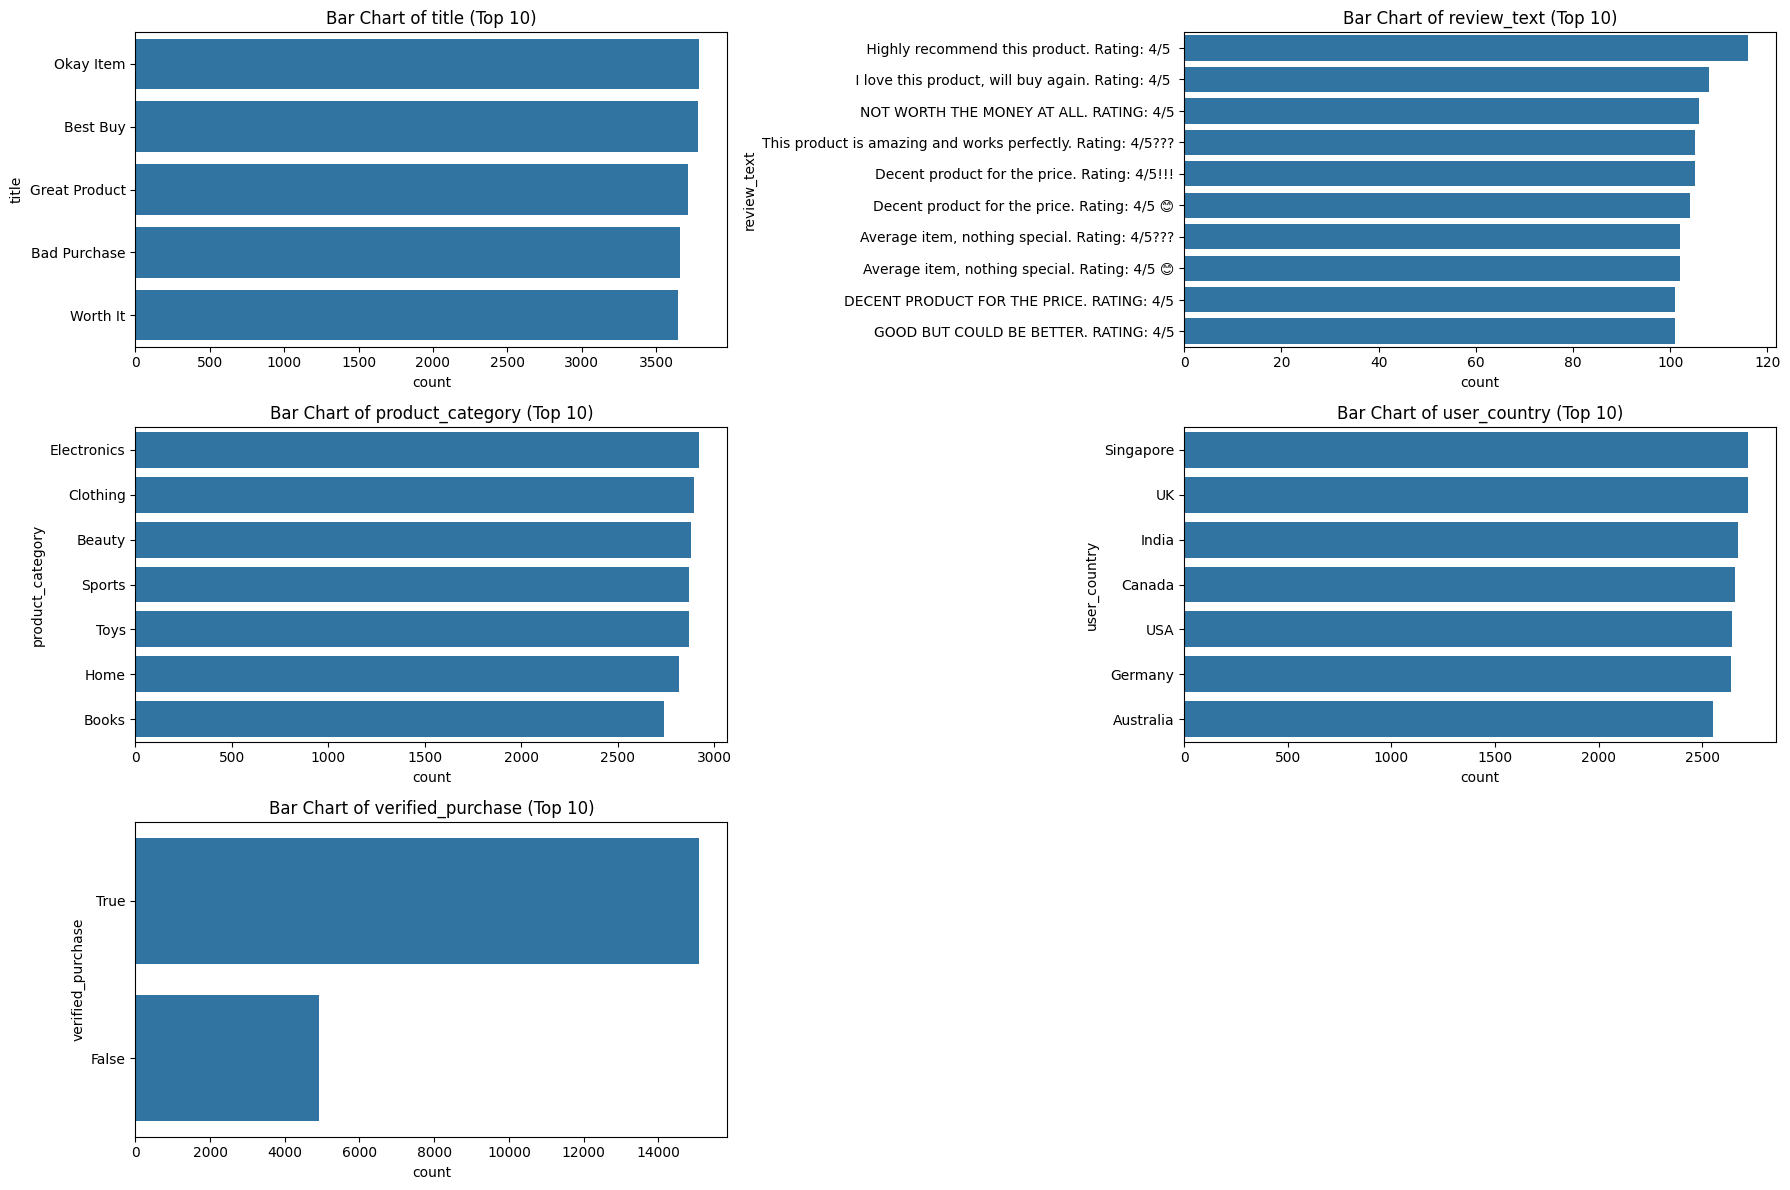

In [26]:
plt.figure(figsize=(18, 12))
for i, col in enumerate(cat_cols):
    plt.subplot(3, 2, i + 1)
    # To save space and get neater plots, we will select only the categories with the 10 largest counts
    top_categories = train[col].value_counts().nlargest(10).index
    sns.countplot(data=train[train[col].isin(top_categories)], y=col, order=top_categories)
    plt.title(f'Bar Chart of {col} (Top 10)')
plt.tight_layout()
plt.savefig('categorical_barcharts.png')
print("Saved 'categorical_barcharts.png'")

## Question 14

Plot a histogram of 'price' column

<Axes: xlabel='price', ylabel='Count'>

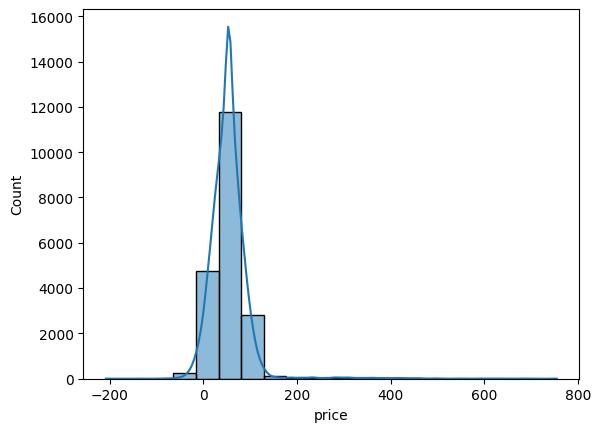

In [27]:
sns.histplot(X.price, bins=20, kde=True)

## Question 15

Plot the correlation heatmap for numeric features

<Axes: >

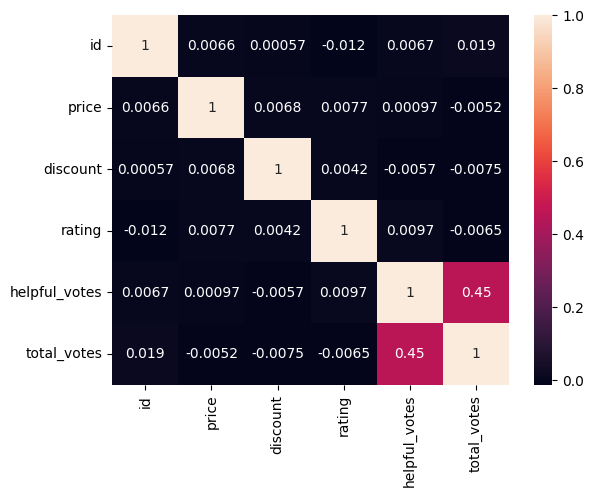

In [28]:
X_numeric = X[num]

sns.heatmap(X_numeric.corr(), annot=True)

## Question 16

**Multivariate Analysis**

Try plotting a pair plot

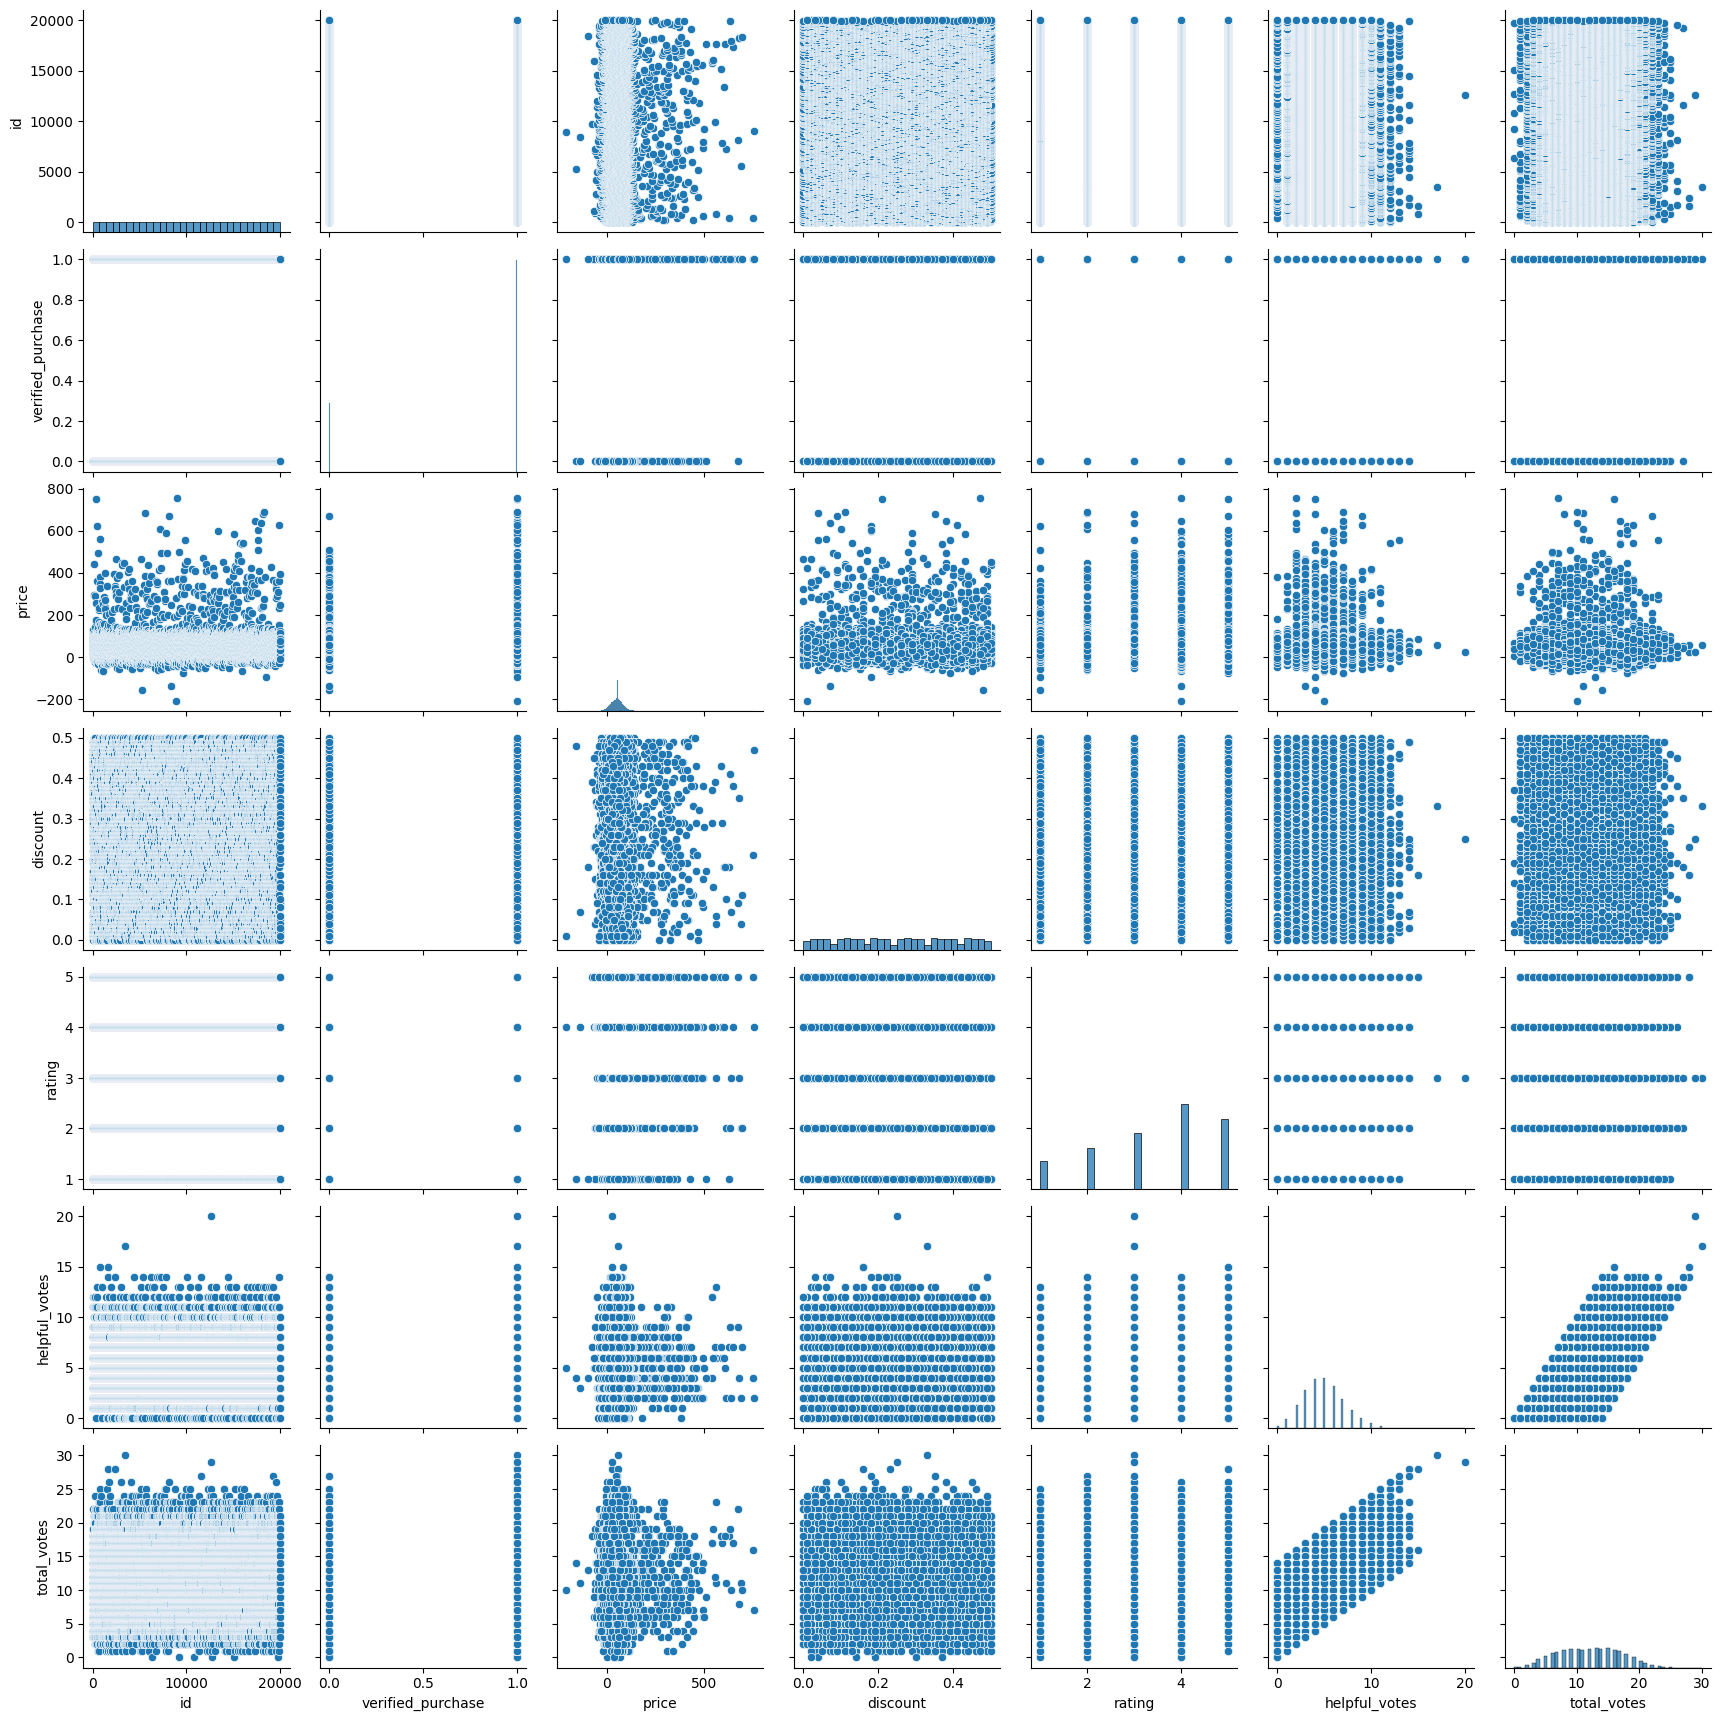

In [29]:
sns.pairplot(X)

## Question 17

Write a single line of Python code using the Seaborn library to create a visualization that meets the following criteria:
- Plot Type: A scatter plot.
- X-axis: Displays the product_category.
- Y-axis: Displays the price.
- Coloring: Distinguish the data points based on their rating using a color legend.

<Axes: xlabel='product_category', ylabel='price'>

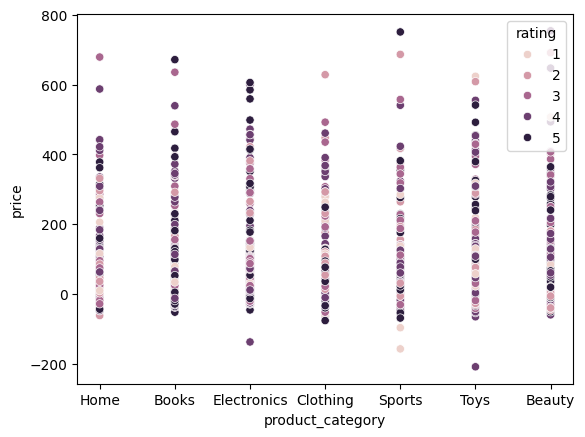

In [30]:
sns.scatterplot(data=X, x="product_category", y="price", hue="rating")

## Question 18

Plot a grouped bar chart which shows the verified vs. not verified purchases broken down by `product_category`

<Axes: xlabel='verified_purchase', ylabel='count'>

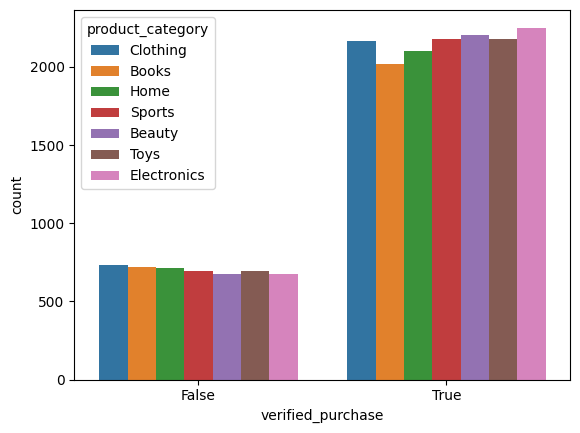

In [31]:
sns.countplot(data=X, x='verified_purchase', hue='product_category')

## Question 19

Identify the outliers on the dataset using IQR score. Use only numeric features for simplicity.

In [32]:
# Calculate Q1 (25th percentile) and Q3 (75th percentile)
Q1 = X_numeric.quantile(0.25)
Q3 = X_numeric.quantile(0.75)

# Calculate the Interquartile Range
IQR = Q3 - Q1

# Define the bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers (rows where any column is outside the bounds)
outliers = ((X_numeric < lower_bound) | (X_numeric > upper_bound)).any(axis=1)

# Extract the outlier rows
outlier_data = X_numeric[outliers]
print(f"Total outliers detected: {outlier_data.shape[0]}")

Total outliers detected: 803


As an additional exercise, identify the outliers using the Z-score method on your own.

## Question 20

**Advanced**

Using the Local Outlier Factor (LOF) method, identify any outliers in the dataset. Create appropriate plots to visualize the outliers. For simplicity, stick to only numerical features of the feature matrix. 

Reference: https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.LocalOutlierFactor.html

In [33]:
from sklearn.neighbors import LocalOutlierFactor

lof = LocalOutlierFactor()

# Fit the model to the training set X and return the labels.
labels = lof.fit_predict(X_numeric)

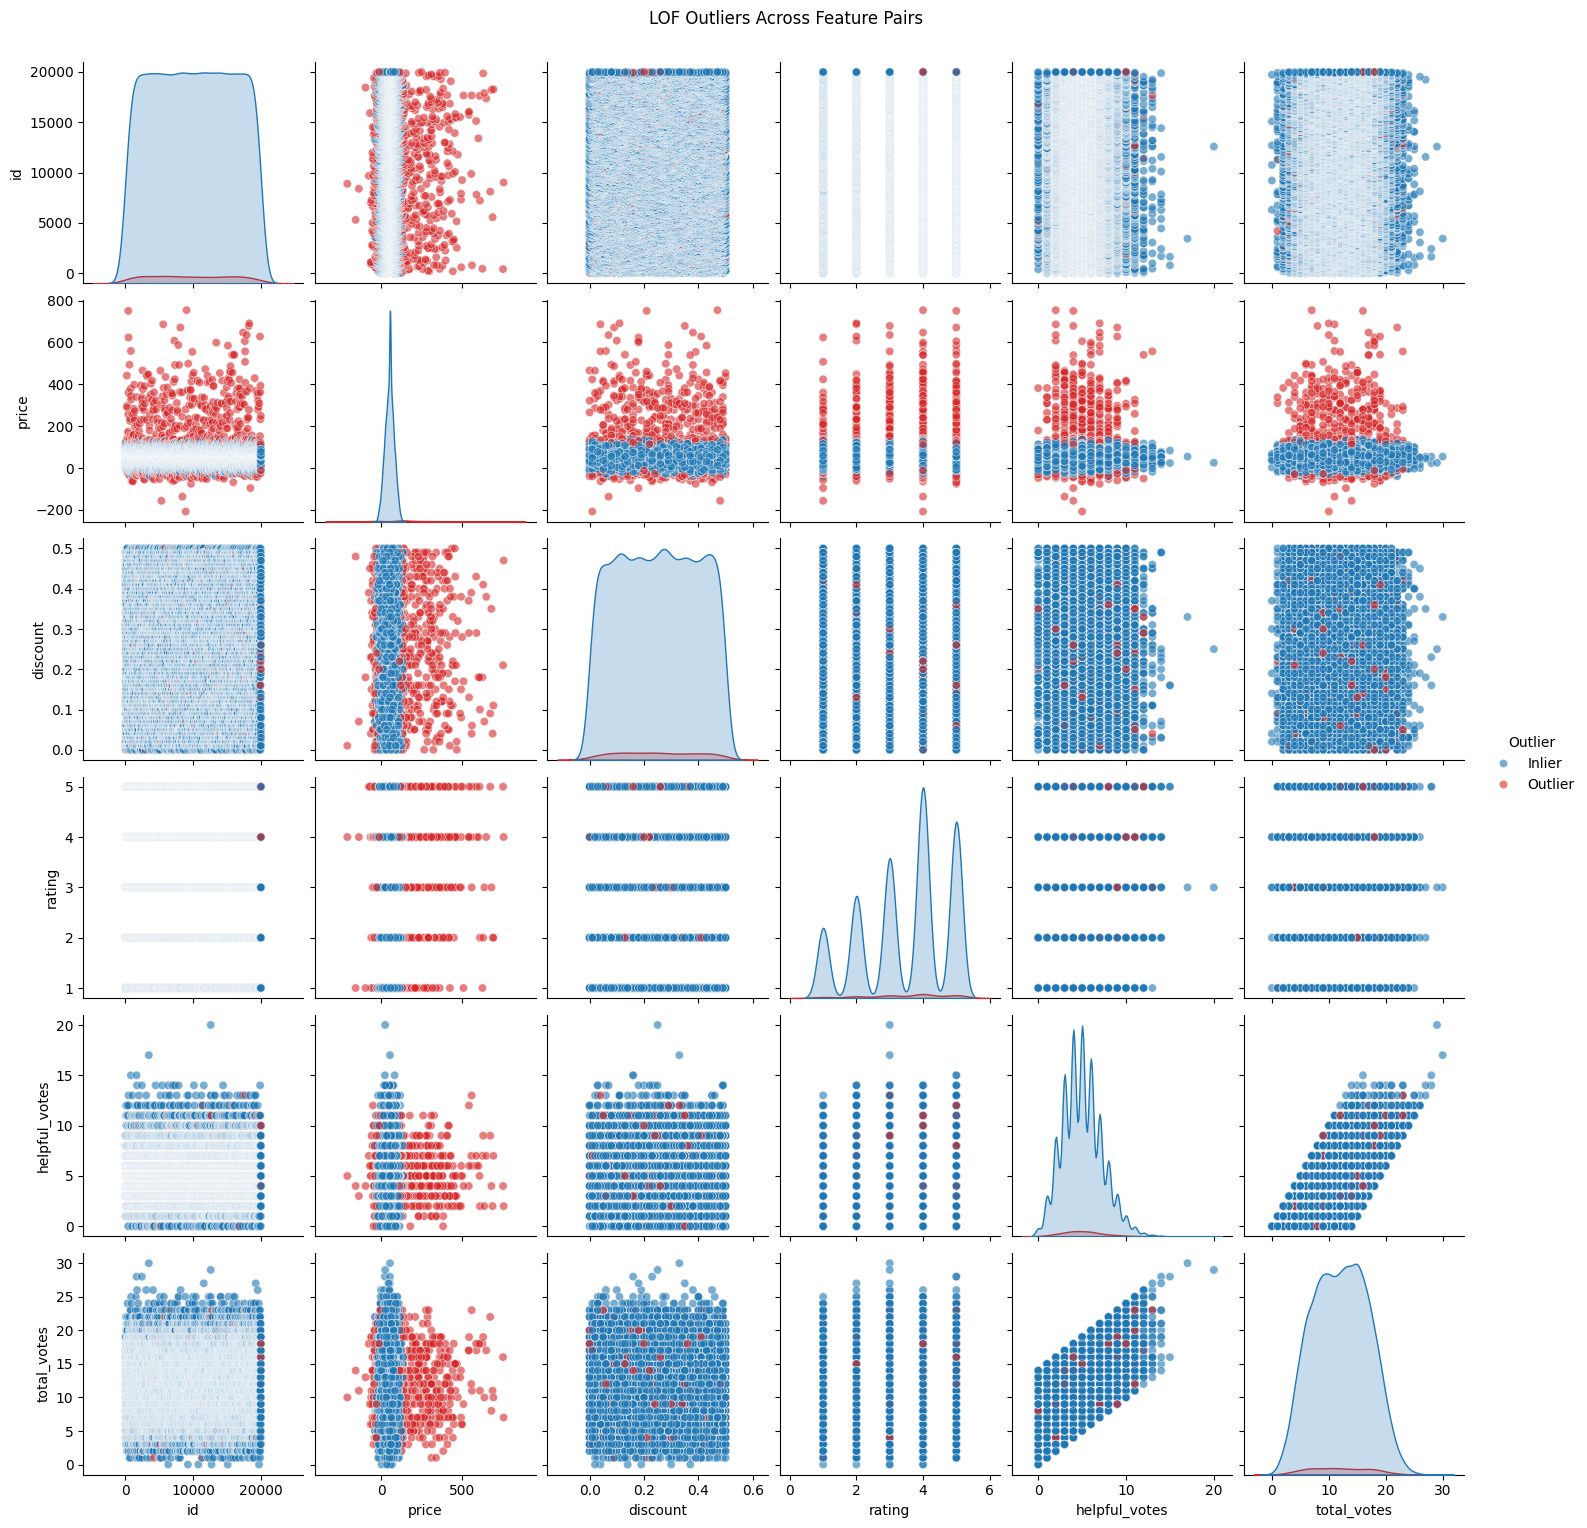

In [34]:
import seaborn as sns

# Add the outlier labels to your original dataframe
X_viz = X_numeric.copy()
X_viz['Outlier'] = lof.fit_predict(X_numeric)

# Map -1/1 to strings for a clearer legend
X_viz['Outlier'] = X_viz['Outlier'].map({1: 'Inlier', -1: 'Outlier'})

# Create the pair plot
sns.pairplot(X_viz, hue='Outlier', palette={'Inlier': '#1f77b4', 'Outlier': '#d62728'}, 
             diag_kind='kde', plot_kws={'alpha': 0.6})
plt.suptitle("LOF Outliers Across Feature Pairs", y=1.02)
plt.show()

# End of Notebook
---